# 피처 엔지니어링

## 라이브러리 불러오기

MAT 파일에서 초기 100사이클의 데이터를 읽고, 셀별 피처를 구성하는 데 필요한 라이브러리를 불러온다.

In [15]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import sys

from hashlib import sha256
from importlib.metadata import version
from scipy.stats import theilslopes
from IPython.display import display

## 데이터 경로 설정

학습·내부 검증에 사용할 Batch 1과 최종 평가에 사용할 Batch 2의 파일 경로를 확인한다.

In [2]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data" / "raw"

batch_paths = {
    "Batch 1": DATA_DIR / "2017-05-12_batchdata_updated_struct_errorcorrect.mat",
    "Batch 2": DATA_DIR / "2018-02-20_batchdata_updated_struct_errorcorrect.mat",
}

for batch_name, path in batch_paths.items():
    if not path.is_file():
        raise FileNotFoundError(f"{batch_name} 파일을 찾을 수 없습니다: {path}")

    print(f"{batch_name}: {path.name} — 확인 완료")

Batch 1: 2017-05-12_batchdata_updated_struct_errorcorrect.mat — 확인 완료
Batch 2: 2018-02-20_batchdata_updated_struct_errorcorrect.mat — 확인 완료


## 수명 타깃과 사이클 기록 확인

제공된 cycle_life와 마지막 기록 사이클, 해당 시점의 방전 용량을 비교한다. 기록 종료를 곧바로 수명 종료로 판단하지 않으며, 차이가 있으면 라벨 정의와 기록 범위를 추가 확인한다.

In [3]:
target_records = []

for batch_name, path in batch_paths.items():
    with h5py.File(path, "r") as f:
        life_refs = f["batch"]["cycle_life"][()].ravel()
        summary_refs = f["batch"]["summary"][()].ravel()

        assert len(life_refs) == len(summary_refs)

        for cell_id, (life_ref, summary_ref) in enumerate(
            zip(life_refs, summary_refs)
        ):
            cycle_life = float(np.asarray(f[life_ref][()]).item())

            summary = f[summary_ref]
            cycle = np.asarray(summary["cycle"][()], dtype=float).ravel()
            qd = np.asarray(summary["QDischarge"][()], dtype=float).ravel()

            assert len(cycle) == len(qd), (
                f"{batch_name}, cell {cell_id}: 배열 길이 불일치"
            )

            # 가장 큰 유효 사이클 번호에 해당하는 기록
            valid_indices = np.flatnonzero(np.isfinite(cycle))

            if len(valid_indices):
                last_idx = valid_indices[np.argmax(cycle[valid_indices])]
                last_cycle = cycle[last_idx]
                last_qd = qd[last_idx]
            else:
                last_cycle = np.nan
                last_qd = np.nan

            target_records.append({
                "batch": batch_name,
                "cell_id": cell_id,
                "cycle_life": cycle_life,
                "n_summary_rows": len(cycle),
                "last_cycle": last_cycle,
                "last_qd": last_qd,
            })

df_target_check = pd.DataFrame(target_records)

df_target_check["life_minus_last_cycle"] = (
    df_target_check["cycle_life"] - df_target_check["last_cycle"]
)

print("배치별 앞 5개 셀")
display(df_target_check.groupby("batch", sort=False).head(5).round(3))

print("수명 타깃과 마지막 기록 사이클의 차이별 셀 수")
display(
    df_target_check.groupby("batch")["life_minus_last_cycle"]
    .value_counts(dropna=False)
    .rename("n_cells")
    .to_frame()
)

배치별 앞 5개 셀


,batch,cell_id,cycle_life,n_summary_rows,last_cycle,last_qd,life_minus_last_cycle
0,Batch 1,0,1190.0,1189,1189.0,1.026,1.0
1,Batch 1,1,1179.0,1178,1178.0,1.038,1.0
2,Batch 1,2,1177.0,1176,1176.0,1.043,1.0
3,Batch 1,3,1226.0,1225,1225.0,0.971,1.0
4,Batch 1,4,1227.0,1226,1226.0,1.022,1.0
46,Batch 2,0,477.0,496,496.0,0.827,-19.0
47,Batch 2,1,491.0,513,513.0,0.828,-22.0
48,Batch 2,2,424.0,439,439.0,0.827,-15.0
49,Batch 2,3,499.0,517,517.0,0.826,-18.0
50,Batch 2,4,444.0,464,464.0,0.827,-20.0


수명 타깃과 마지막 기록 사이클의 차이별 셀 수


n_cells
batch   life_minus_last_cycle         
Batch 1  1.0                        46
Batch 2  NaN                         8
        -18.0                        6
        -19.0                        5
        -23.0                        3
        -27.0                        3
        -21.0                        2
        -17.0                        2
        -29.0                        2
        -20.0                        2
        -22.0                        2
        -32.0                        1
        -66.0                        1
        -50.0                        1
        -25.0                        1
        -26.0                        1
        -35.0                        1
        -33.0                        1
        -28.0                        1
        -43.0                        1
        -16.0                        1
        -15.0                        1
        -30.0                        1

## 기록 종료 시점의 용량 확인

Batch 1의 마지막 방전 용량을 10사이클 용량과 비교한다. 종료 용량 비율이 높은 셀의 전체 곡선을 살펴보고, 제공된 수명과 기록 종료의 관계를 추가 점검한다.

10사이클 용량은 비교용 기준이며, 이 결과만으로 EOL 도달 여부나 기록 연장을 확정하지 않는다.

종료 용량 비율이 높은 상위 10셀


,cell_id,cycle_life,last_cycle,qd_10,last_qd,last_vs_qd10_pct
2,2,1177.0,1176.0,1.084,1.043,96.263
1,1,1179.0,1178.0,1.080,1.038,96.152
0,0,1190.0,1189.0,1.075,1.026,95.502
4,4,1227.0,1226.0,1.082,1.022,94.455
3,3,1226.0,1225.0,1.084,0.971,89.543
10,10,906.0,905.0,1.080,0.961,89.021
22,22,891.0,890.0,1.083,0.963,88.943
8,8,879.0,878.0,1.094,0.969,88.565
13,13,897.0,896.0,1.084,0.923,85.184
12,12,902.0,901.0,1.081,0.913,84.459


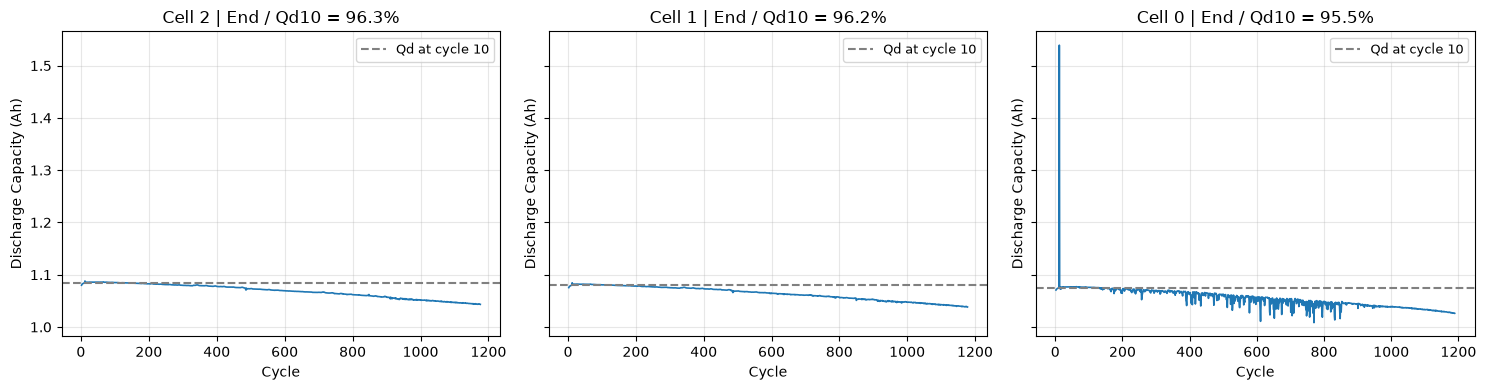

In [5]:
reference_records = []
batch1_curves = {}

with h5py.File(batch_paths["Batch 1"], "r") as f:
    summary_refs = f["batch"]["summary"][()].ravel()

    for cell_id, ref in enumerate(summary_refs):
        summary = f[ref]

        cycle = np.asarray(summary["cycle"][()], dtype=float).ravel()
        qd = np.asarray(summary["QDischarge"][()], dtype=float).ravel()

        assert len(cycle) == len(qd)

        idx10 = np.flatnonzero(cycle == 10)
        qd10 = qd[idx10[0]] if len(idx10) == 1 else np.nan

        reference_records.append({
            "cell_id": cell_id,
            "qd_10": qd10,
        })

        # 첫 사이클의 빈 용량 기록과 비유한 값만 표시에서 제외
        valid = (
            np.isfinite(cycle)
            & np.isfinite(qd)
            & ~((cycle == 1) & (qd == 0))
        )
        batch1_curves[cell_id] = (cycle[valid], qd[valid])

df_end_check = (
    df_target_check.loc[df_target_check["batch"] == "Batch 1"]
    .merge(
        pd.DataFrame(reference_records),
        on="cell_id",
        how="left",
        validate="one_to_one",
    )
)

valid_capacity = (
    np.isfinite(df_end_check["qd_10"])
    & np.isfinite(df_end_check["last_qd"])
    & df_end_check["qd_10"].gt(0)
    & df_end_check["last_qd"].gt(0)
)

df_end_check["last_vs_qd10_pct"] = (
    100 * df_end_check["last_qd"] / df_end_check["qd_10"]
).where(valid_capacity)

df_end_check = df_end_check.sort_values(
    ["last_vs_qd10_pct", "cell_id"],
    ascending=[False, True],
)

print("종료 용량 비율이 높은 상위 10셀")
display(
    df_end_check[
        [
            "cell_id",
            "cycle_life",
            "last_cycle",
            "qd_10",
            "last_qd",
            "last_vs_qd10_pct",
        ]
    ].head(10).round(3)
)

# 종료 용량 비율이 높은 3셀을 의도적으로 선택해 확인
selected = df_end_check.dropna(subset=["last_vs_qd10_pct"]).head(3)

if not selected.empty:
    fig, axes = plt.subplots(
        1, len(selected),
        figsize=(5 * len(selected), 4),
        sharey=True,
        squeeze=False,
    )

    for ax, row in zip(axes.ravel(), selected.itertuples(index=False)):
        cycle, qd = batch1_curves[row.cell_id]

        ax.plot(cycle, qd, linewidth=1.2)
        ax.axhline(
            row.qd_10,
            color="gray",
            linestyle="--",
            label="Qd at cycle 10",
        )
        ax.set_title(
            f"Cell {row.cell_id} | End / Qd10 = "
            f"{row.last_vs_qd10_pct:.1f}%"
        )
        ax.set_xlabel("Cycle")
        ax.set_ylabel("Discharge Capacity (Ah)")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=9)

    plt.tight_layout()
    plt.show()

### 확인 결과와 판단

Batch 1의 셀 0·1·2·4는 기록 종료 시점에도 10사이클 용량의 약 94.5~96.3%를 유지했다. 종료 용량 비율이 높은 상위 3셀의 곡선에서도 완만한 감소 이후 기록이 끝나는 형태가 관찰됐다.

따라서 현재 파일의 기록 종료와 실제 수명 종료가 동일한지 추가 확인이 필요하다. 기록 중단·다른 파일로의 연장·라벨 생성 방식은 아직 확인되지 않았으므로, 제공된 cycle_life를 임의로 보정하거나 해당 셀을 제외하지 않는다.

셀 0에서는 순간적인 용량 급등과 반복적인 하락이 관찰된다. 이는 별도의 데이터 품질 점검 대상으로 남긴다. 10사이클 대비 종료 용량 비율은 진단용이며, 공식 SOH나 모델 입력 피처로 사용하지 않는다.

## 배치 간 셀 식별정보 확인

barcode의 결측과 중복을 확인하고, Batch 1·2 사이에 같은 식별자가 있는지 비교한다. 일치하는 값은 동일 셀 또는 공통 표기인지 추가 확인하며, 일치 여부만으로 기록 연장을 확정하지 않는다.

In [8]:
barcode_records = []

for batch_name, path in batch_paths.items():
    with h5py.File(path, "r") as f:
        # MATLAB 문자열 객체의 연결 정보를 읽는다.
        mcos = f["#subsystem#/MCOS"][()].ravel()
        metadata = f[mcos[0]][()].tobytes()

        if int.from_bytes(metadata[:4], "little") != 2:
            raise ValueError("지원하지 않는 MATLAB 문자열 저장 형식입니다.")

        offsets = np.frombuffer(metadata, dtype="<u4", count=8, offset=8)

        names = [
            value.decode("ascii")
            for value in metadata[40:int(offsets[0])].split(b"\x00")
            if value
        ]

        props = np.frombuffer(
            metadata[int(offsets[1]):int(offsets[2])], dtype="<u4"
        )
        objects = np.frombuffer(
            metadata[int(offsets[2]):int(offsets[3])], dtype="<u4"
        ).reshape(-1, 6)

        for cell_id, ref in enumerate(f["batch"]["barcode"][()].ravel()):
            dataset = f[ref]
            handle = dataset[()].ravel()

            if (
                dataset.attrs.get("MATLAB_class") != b"string"
                or handle.size != 6
                or handle[:4].tolist() != [3707764736, 2, 1, 1]
            ):
                raise ValueError(f"{batch_name}, 셀 {cell_id}: 형식 확인 필요")

            # 객체 ID로 실제 문자열이 저장된 위치를 찾는다.
            save_id = int(objects[int(handle[4]), 3])
            if save_id <= 0:
                raise ValueError("문자열 속성을 찾지 못했습니다.")

            cursor = int(props[0])
            for _ in range(save_id):
                cursor += 1 + 3 * int(props[cursor])
                cursor += cursor % 2

            n_props = int(props[cursor])
            fields = props[
                cursor + 1:cursor + 1 + 3 * n_props
            ].reshape(-1, 3)

            values = [
                int(value)
                for name, kind, value in fields
                if names[int(name) - 1] == "any" and int(kind) == 1
            ]
            if len(values) != 1:
                raise ValueError("문자열 원본 참조를 확인하세요.")

            raw = f[mcos[2 + values[0]]][()].ravel()
            if raw.dtype != np.dtype("<u8") or raw[:4].tolist() != [1, 2, 1, 1]:
                raise ValueError("지원하지 않는 문자열 데이터입니다.")

            # 내부 정보는 제외하고 실제 문자열 부분만 해독한다.
            length = int(raw[4])
            if length == np.iinfo(np.uint64).max:
                barcode = None
            else:
                if 2 * length > raw[5:].nbytes:
                    raise ValueError("문자열 길이가 맞지 않습니다.")

                barcode = (
                    raw[5:].tobytes()[:2 * length]
                    .decode("utf-16le").strip()
                ) or None

                if barcode is not None and not barcode.isprintable():
                    raise ValueError("barcode에 잘못된 문자가 포함되어 있습니다.")

            barcode_records.append({
                "batch": batch_name,
                "cell_id": cell_id,
                "barcode": barcode,
            })

df_cell_info = pd.DataFrame(barcode_records)

# 실제 barcode가 문자열로 읽혔는지 확인
print("배치별 barcode 예시")
display(df_cell_info.groupby("batch").head(3))

# 배치별 식별정보 현황
barcode_summary = df_cell_info.groupby("batch").agg(
    total_cells=("cell_id", "size"),
    available_barcode=("barcode", "count"),
    unique_barcode=("barcode", "nunique"),
)
barcode_summary["missing_barcode"] = (
    barcode_summary["total_cells"] - barcode_summary["available_barcode"]
)

print("배치별 barcode 현황")
display(barcode_summary)

# 결측 식별자는 중복 비교에서 제외
valid_barcodes = df_cell_info.dropna(subset=["barcode"]).copy()

# 서로 다른 배치에서 나타나는 barcode
batch_counts = valid_barcodes.groupby("barcode")["batch"].nunique()
shared_barcodes = batch_counts[batch_counts > 1].index

cross_batch_matches = valid_barcodes.loc[
    valid_barcodes["barcode"].isin(shared_barcodes)
].sort_values(["barcode", "batch", "cell_id"])

print("두 배치에 공통으로 나타나는 barcode 수:", len(shared_barcodes))
display(cross_batch_matches)

# 같은 배치 안에서 반복되는 barcode
within_batch_duplicates = valid_barcodes.loc[
    valid_barcodes.duplicated(["batch", "barcode"], keep=False)
].sort_values(["batch", "barcode", "cell_id"])

print("배치 내부에서 barcode가 중복된 셀 기록 수:", len(within_batch_duplicates))
display(within_batch_duplicates)

배치별 barcode 예시


,batch,cell_id,barcode
0,Batch 1,0,EL150800460514
1,Batch 1,1,EL150800460486
2,Batch 1,2,EL150800460623
46,Batch 2,0,EL150800737291
47,Batch 2,1,EL150800737295
48,Batch 2,2,EL150800720603


배치별 barcode 현황


,total_cells,available_barcode,unique_barcode,missing_barcode
batch,,,,
Batch 1,46,46,46,0
Batch 2,47,47,47,0


두 배치에 공통으로 나타나는 barcode 수: 0


,batch,cell_id,barcode


배치 내부에서 barcode가 중복된 셀 기록 수: 0


,batch,cell_id,barcode


- Batch 1의 46셀과 Batch 2의 47셀 모두 barcode가 존재하며, 결측은 없다.
- 배치 내부와 두 배치 사이에서 중복 barcode는 발견되지 않았다.
- barcode는 셀 식별과 중복 확인에만 사용하고, 모델 입력 피처에서는 제외한다.

## 초기 사이클 요약 피처 추출

10~100사이클의 방전 용량 변화, 내부저항, 온도, 충전시간과 초기 용량 감소율을 셀별로 추출하고 결측 여부를 확인한다.

In [9]:
median_features = {
    "IR": "ir_median",
    "Tavg": "tavg_median",
    "Tmax": "tmax_median",
    "chargetime": "chargetime_median",
}

summary_feature_cols = [
    "qd_10",
    "qd_change_100_10",
    *median_features.values(),
    "early_fade_rate",
]

summary_records = []
quality_records = []

for batch_name, path in batch_paths.items():
    with h5py.File(path, "r") as f:
        summary_refs = f["batch"]["summary"][()].ravel()

        for cell_id, ref in enumerate(summary_refs):
            summary = f[ref]

            arrays = {
                name: np.asarray(summary[name][()], dtype=float).ravel()
                for name in ["cycle", "QDischarge", *median_features]
            }

            if len({len(values) for values in arrays.values()}) != 1:
                raise ValueError(
                    f"{batch_name}, 셀 {cell_id}: summary 배열 길이 불일치"
                )

            # 실제 사이클 번호를 기준으로 관측 범위를 제한
            early = pd.DataFrame(arrays)
            early = (
                early.loc[early["cycle"].between(10, 100)]
                .set_index("cycle")
                .sort_index()
                .replace([np.inf, -np.inf], np.nan)
            )

            if early.index.duplicated().any():
                raise ValueError(
                    f"{batch_name}, 셀 {cell_id}: 중복 사이클 번호 확인 필요"
                )

            qd = early["QDischarge"]
            qd10 = qd.get(10, np.nan)
            qd100 = qd.get(100, np.nan)

            record = {
                "batch": batch_name,
                "cell_id": cell_id,
                "qd_10": qd10,
                "qd_change_100_10": qd100 - qd10,
            }

            # 내부저항·온도·충전시간의 유효값 중앙값
            for source, feature in median_features.items():
                valid_values = early[source].dropna()
                record[feature] = (
                    valid_values.median()
                    if len(valid_values) > 0
                    else np.nan
                )

            # 초기 용량 감소율: 양수는 감소, 음수는 증가
            valid_qd = qd.dropna()

            if (
                len(valid_qd) >= 3
                and 10 in valid_qd.index
                and 100 in valid_qd.index
            ):
                slope = theilslopes(
                    valid_qd.to_numpy(),
                    valid_qd.index.to_numpy(dtype=float),
                )[0]
                record["early_fade_rate"] = -1000 * slope  # mAh/cycle
            else:
                record["early_fade_rate"] = np.nan

            summary_records.append(record)

            # 유효 기록 수는 품질 점검용이며 모델 피처에 포함하지 않음
            quality_records.append({
                "batch": batch_name,
                "cell_id": cell_id,
                **early.count().to_dict(),
            })

df_summary_features = pd.DataFrame(summary_records)
df_summary_quality = pd.DataFrame(quality_records)

print("배치별 피처 추출 셀 수")
display(
    df_summary_features.groupby("batch").size().to_frame("n_cells")
)

print("배치별 앞 3개 셀의 피처")
display(
    df_summary_features.groupby("batch").head(3).round(6)
)

print("배치별 피처 결측 셀 수")
display(
    df_summary_features[summary_feature_cols]
    .isna()
    .groupby(df_summary_features["batch"])
    .sum()
)

# 10~100사이클은 양 끝을 포함해 91개 기록
measurement_cols = ["QDischarge", *median_features]
incomplete = df_summary_quality.loc[
    df_summary_quality[measurement_cols].lt(91).any(axis=1)
]

print("측정값의 유효 기록이 91개 미만인 셀 수:", len(incomplete))
if not incomplete.empty:
    display(incomplete)

배치별 피처 추출 셀 수


,n_cells
batch,
Batch 1,46
Batch 2,47


배치별 앞 3개 셀의 피처


,batch,cell_id,qd_10,qd_change_100_10,ir_median,tavg_median,tmax_median,chargetime_median,early_fade_rate
0,Batch 1,0,1.074537,0.001375,0.016618,31.563844,35.349518,13.358212,0.005659
1,Batch 1,1,1.079777,0.000853,0.016924,31.250887,34.101273,13.341540,0.015812
2,Batch 1,2,1.083782,0.001159,0.016772,31.403896,34.505478,13.341597,0.006071
46,Batch 2,0,1.103718,0.001554,0.017349,31.825906,35.418743,10.173175,-0.017307
47,Batch 2,1,1.108311,-0.006769,0.017500,33.640642,36.482052,10.176748,0.019833
48,Batch 2,2,1.078596,-0.005760,0.016433,33.195518,37.492191,10.174892,0.015070


배치별 피처 결측 셀 수


,qd_10,qd_change_100_10,ir_median,tavg_median,tmax_median,chargetime_median,early_fade_rate
batch,,,,,,,
Batch 1,0,0,0,0,0,0,0
Batch 2,0,0,0,0,0,0,0


측정값의 유효 기록이 91개 미만인 셀 수: 0


## ΔQ(V) 피처 추출

동일한 전압축에서 100사이클과 10사이클의 Q(V) 차이를 계산하고, 평균·최솟값·로그 분산을 셀별로 추출한다.

In [10]:
delta_feature_cols = [
    "delta_q_mean",
    "delta_q_min",
    "delta_q_log_var",
]

delta_records = []
delta_issues = []
delta_voltage_grid = None

for batch_name, path in batch_paths.items():
    with h5py.File(path, "r") as f:
        batch = f["batch"]
        cycle_refs = batch["cycles"][()].ravel()
        summary_refs = batch["summary"][()].ravel()
        voltage_refs = batch["Vdlin"][()].ravel()

        if not (
            len(cycle_refs) == len(summary_refs) == len(voltage_refs)
        ):
            raise ValueError(f"{batch_name}: 셀별 참조 수가 다릅니다.")

        for cell_id, cycle_ref in enumerate(cycle_refs):
            record = {
                "batch": batch_name,
                "cell_id": cell_id,
                **{feature: np.nan for feature in delta_feature_cols},
            }

            try:
                if not all([
                    cycle_ref, summary_refs[cell_id], voltage_refs[cell_id]
                ]):
                    raise ValueError("사이클·요약·전압축 참조 없음")

                cycles = f[cycle_ref]
                summary = f[summary_refs[cell_id]]

                q_refs = cycles["Qdlin"][()].ravel()
                cycle_numbers = np.asarray(
                    summary["cycle"][()], dtype=float
                ).ravel()

                # 실제 사이클 번호로 위치 확인
                idx10 = np.flatnonzero(cycle_numbers == 10)
                idx100 = np.flatnonzero(cycle_numbers == 100)

                if (
                    len(q_refs) != len(cycle_numbers)
                    or len(idx10) != 1
                    or len(idx100) != 1
                ):
                    raise ValueError("사이클 번호 또는 기록 수 확인 필요")

                refs = [
                    voltage_refs[cell_id],
                    q_refs[idx10[0]],
                    q_refs[idx100[0]],
                ]

                if not all(refs):
                    raise ValueError("전압축 또는 Qdlin 참조 없음")

                voltage, q10, q100 = [
                    np.asarray(f[ref][()], dtype=float).ravel()
                    for ref in refs
                ]

                if not (len(voltage) == len(q10) == len(q100) == 1000):
                    raise ValueError("전압축과 Qdlin의 1000점 길이 확인 필요")

                if not all(
                    np.isfinite(values).all()
                    for values in [voltage, q10, q100]
                ):
                    raise ValueError("전압축 또는 Qdlin에 결측·무한값 존재")

                voltage_diff = np.diff(voltage)
                if not (
                    np.all(voltage_diff > 0)
                    or np.all(voltage_diff < 0)
                ):
                    raise ValueError("전압축 순서 또는 중복값 확인 필요")

                # 전압과 두 곡선을 같은 순서로 정렬
                order = np.argsort(voltage)
                voltage = voltage[order]
                delta_q = q100[order] - q10[order]

                # 셀 사이에서도 같은 전압 좌표를 사용하는지 확인
                if delta_voltage_grid is None:
                    delta_voltage_grid = voltage.copy()
                elif not np.allclose(
                    voltage, delta_voltage_grid, rtol=0, atol=1e-10
                ):
                    raise ValueError("기준 전압축과 좌표가 다름")

                delta_var = np.var(delta_q, ddof=0)
                if not np.isfinite(delta_var):
                    raise ValueError("분산 계산값 확인 필요")

                record.update({
                    "delta_q_mean": np.mean(delta_q),
                    "delta_q_min": np.min(delta_q),
                    "delta_q_log_var": (
                        np.log10(delta_var) if delta_var > 0 else np.nan
                    ),
                })

                if delta_var == 0:
                    delta_issues.append({
                        "batch": batch_name,
                        "cell_id": cell_id,
                        "reason": "분산이 0이므로 로그 분산만 결측 처리",
                    })

            except (KeyError, ValueError) as error:
                delta_issues.append({
                    "batch": batch_name,
                    "cell_id": cell_id,
                    "reason": str(error),
                })

            # 계산 실패 셀도 행을 유지
            delta_records.append(record)

df_delta_features = pd.DataFrame(delta_records)

print("배치별 ΔQ 피처 추출 현황")
display(
    df_delta_features.groupby("batch").agg(
        total_cells=("cell_id", "size"),
        available_mean=("delta_q_mean", "count"),
        available_min=("delta_q_min", "count"),
        available_log_var=("delta_q_log_var", "count"),
    )
)

print("배치별 앞 3개 셀의 ΔQ 피처")
display(
    df_delta_features.groupby("batch").head(3).round(6)
)

print("점검이 필요한 셀 수:", len(delta_issues))
if delta_issues:
    display(pd.DataFrame(delta_issues))

배치별 ΔQ 피처 추출 현황


,total_cells,available_mean,available_min,available_log_var
batch,,,,
Batch 1,46,46,46,46
Batch 2,47,47,47,47


배치별 앞 3개 셀의 ΔQ 피처


,batch,cell_id,delta_q_mean,delta_q_min,delta_q_log_var
0,Batch 1,0,-0.002873,-0.008460,-5.014861
1,Batch 1,1,-0.004100,-0.011004,-5.013960
2,Batch 1,2,-0.004487,-0.017216,-4.737000
46,Batch 2,0,-0.025801,-0.055061,-3.487265
47,Batch 2,1,-0.035595,-0.066115,-3.298051
48,Batch 2,2,-0.025013,-0.052718,-3.460248


점검이 필요한 셀 수: 0


## 충전 조건 피처 추출

충전 프로토콜에서 1단계 C-rate, 2단계 C-rate와 전환 SOC를 추출한다. 일반적인 2단계 형식으로 해석되지 않는 프로토콜은 원문을 보존하고 별도로 확인한다.

In [11]:
charge_records = []

for batch_name, path in batch_paths.items():
    with h5py.File(path, "r") as f:
        policy_refs = f["batch"]["policy_readable"][()].ravel()

        for cell_id, ref in enumerate(policy_refs):
            protocol = None

            if ref:
                dataset = f[ref]

                if not dataset.attrs.get("MATLAB_empty", False):
                    if dataset.attrs.get("MATLAB_class") != b"char":
                        raise ValueError(
                            f"{batch_name}, 셀 {cell_id}: 문자 배열 형식 확인 필요"
                        )

                    raw = np.asarray(dataset[()])
                    if raw.dtype.kind != "u" or raw.dtype.itemsize != 2:
                        raise ValueError(
                            f"{batch_name}, 셀 {cell_id}: 문자 자료형 확인 필요"
                        )

                    protocol = (
                        raw.astype("<u2").ravel().tobytes()
                        .decode("utf-16le")
                        .strip("\x00 \t\r\n")
                    ) or None

            charge_records.append({
                "batch": batch_name,
                "cell_id": cell_id,
                "protocol": protocol,
            })

df_charge_features = pd.DataFrame(charge_records)

# 일반적인 2단계 충전 프로토콜 해석
# 예: 5.6C(26%)-4.5C-newstructure
number = r"\d+(?:\.\d+)?"
pattern = (
    rf"^(?P<charge_c1>{number})C"
    rf"\((?P<switch_soc>{number})%\)-"
    rf"(?P<charge_c2>{number})C"
    rf"(?:-(?P<protocol_note>.*))?$"
)

parsed = (
    df_charge_features["protocol"]
    .str.replace(" ", "", regex=False)
    .str.extract(pattern)
)

charge_feature_cols = ["charge_c1", "charge_c2", "switch_soc"]

for column in charge_feature_cols:
    df_charge_features[column] = pd.to_numeric(
        parsed[column], errors="coerce"
    )

# 추가 표기를 보존하며 숫자 피처에는 포함하지 않음
df_charge_features["protocol_note"] = parsed["protocol_note"]

parsed_mask = df_charge_features[charge_feature_cols].notna().all(axis=1)

print("배치별 충전 조건 추출 현황")
charge_summary = (
    df_charge_features.assign(parsed=parsed_mask)
    .groupby("batch")
    .agg(
        total_cells=("cell_id", "size"),
        parsed_cells=("parsed", "sum"),
    )
)
charge_summary["unparsed_cells"] = (
    charge_summary["total_cells"] - charge_summary["parsed_cells"]
)
display(charge_summary)

print("배치별 앞 3개 셀의 충전 조건")
display(
    df_charge_features.groupby("batch").head(3)[
        ["batch", "cell_id", "protocol", *charge_feature_cols]
    ]
)

unparsed = df_charge_features.loc[
    ~parsed_mask, ["batch", "cell_id", "protocol"]
].copy()

unparsed["reason"] = np.where(
    unparsed["protocol"].isna(),
    "충전 프로토콜 없음",
    "일반적인 2단계 형식과 불일치",
)

print("숫자 피처로 해석되지 않은 셀 수:", len(unparsed))
if not unparsed.empty:
    display(unparsed)

배치별 충전 조건 추출 현황


,total_cells,parsed_cells,unparsed_cells
batch,,,
Batch 1,46,46,0
Batch 2,47,39,8


배치별 앞 3개 셀의 충전 조건


,batch,cell_id,protocol,charge_c1,charge_c2,switch_soc
0,Batch 1,0,3.6C(80%)-3.6C,3.6,3.60,80.0
1,Batch 1,1,3.6C(80%)-3.6C,3.6,3.60,80.0
2,Batch 1,2,3.6C(80%)-3.6C,3.6,3.60,80.0
46,Batch 2,0,5.2C(58%)-4C,5.2,4.00,58.0
47,Batch 2,1,5.6C(26%)-4.5C,5.6,4.50,26.0
48,Batch 2,2,5.2C(50%)-4.25C,5.2,4.25,50.0


숫자 피처로 해석되지 않은 셀 수: 8


,batch,cell_id,protocol,reason
68,Batch 2,22,VarCharge-2C-100cycles,일반적인 2단계 형식과 불일치
69,Batch 2,23,VarCharge-4C-100cycles,일반적인 2단계 형식과 불일치
81,Batch 2,35,VarCharge-6C-100cycles,일반적인 2단계 형식과 불일치
82,Batch 2,36,VarCharge-8C-100cycles,일반적인 2단계 형식과 불일치
83,Batch 2,37,3.6C(80%)-3.6C(SLOWCYCLE,일반적인 2단계 형식과 불일치
84,Batch 2,38,4.8C(80%)-4.8C(SLOWCYCLE,일반적인 2단계 형식과 불일치
85,Batch 2,39,3.6C(9%)-5C(SLOWCYCLE,일반적인 2단계 형식과 불일치
86,Batch 2,40,5.2C(58%)-4C(SLOWCYCLE,일반적인 2단계 형식과 불일치


## 셀별 피처와 타깃 결합

배치와 셀 ID를 기준으로 피처 후보와 수명 타깃을 결합한다. 키의 중복·누락을 확인하고, 수명값이 있는 셀과 없는 셀을 구분한다.

In [12]:
keys = ["batch", "cell_id"]

# 모델 입력 후보만 명시
feature_cols = (
    summary_feature_cols
    + delta_feature_cols
    + charge_feature_cols
)

tables = {
    "식별정보": df_cell_info[keys + ["barcode"]],
    "수명": df_target_check[keys + ["cycle_life"]],
    "요약 피처": df_summary_features[keys + summary_feature_cols],
    "ΔQ 피처": df_delta_features[keys + delta_feature_cols],
    "충전 조건": df_charge_features[
        keys + ["protocol", "protocol_note"] + charge_feature_cols
    ],
}

# 결합 전에 모든 표가 동일한 셀을 포함하는지 확인
expected_keys = set(
    tables["식별정보"][keys].itertuples(index=False, name=None)
)

for name, table in tables.items():
    if table[keys].isna().any().any():
        raise ValueError(f"{name}: 배치 또는 셀 ID에 결측이 있습니다.")

    if table.duplicated(keys).any():
        raise ValueError(f"{name}: 중복된 배치·셀 ID가 있습니다.")

    current_keys = set(
        table[keys].itertuples(index=False, name=None)
    )

    if current_keys != expected_keys:
        raise ValueError(
            f"{name}: 셀 누락 {len(expected_keys - current_keys)}개, "
            f"추가 {len(current_keys - expected_keys)}개"
        )

# 셀별 1:1 결합
df_features = tables["식별정보"].copy()

for table in list(tables.values())[1:]:
    df_features = df_features.merge(
        table,
        on=keys,
        how="left",
        validate="one_to_one",
    )

df_features = (
    df_features[
        keys
        + ["barcode", "protocol", "protocol_note", "cycle_life"]
        + feature_cols
    ]
    .sort_values(keys)
    .reset_index(drop=True)
)

# 입력 피처의 무한값은 결측으로 표시
df_features[feature_cols] = df_features[feature_cols].replace(
    [np.inf, -np.inf], np.nan
)

# 수명 타깃은 자동 수정하지 않고 이상 여부 확인
target = df_features["cycle_life"]
invalid_target = target.notna() & (
    ~np.isfinite(target) | target.le(100)
)

if invalid_target.any():
    display(df_features.loc[invalid_target, keys + ["cycle_life"]])
    raise ValueError("수명값과 초기 100사이클 관측 범위를 확인하세요.")

# 수명값의 존재 여부로 구분하며, 입력 결측으로 행을 삭제하지 않음
has_target = target.notna()
df_labeled = df_features.loc[has_target].copy()
df_unlabeled = df_features.loc[~has_target].copy()

print("피처 후보 수:", len(feature_cols))
print("전체 결합표 크기:", df_features.shape)

print("배치별 결합 결과")
merge_summary = (
    df_features.assign(
        has_target=has_target,
        missing_features=df_features[feature_cols].isna().any(axis=1),
    )
    .groupby("batch")
    .agg(
        total_cells=("cell_id", "size"),
        labeled_cells=("has_target", "sum"),
        cells_with_missing_features=("missing_features", "sum"),
    )
)
merge_summary["unlabeled_cells"] = (
    merge_summary["total_cells"] - merge_summary["labeled_cells"]
)
display(merge_summary)

print("수명값이 없는 셀")
display(
    df_unlabeled[keys + ["protocol", "cycle_life"]]
)

print("수명값이 있는 셀의 피처별 결측 수")
display(
    df_labeled[feature_cols]
    .isna()
    .groupby(df_labeled["batch"])
    .sum()
    .T
)

피처 후보 수: 13
전체 결합표 크기: (93, 19)
배치별 결합 결과


,total_cells,labeled_cells,cells_with_missing_features,unlabeled_cells
batch,,,,
Batch 1,46,46,0,0
Batch 2,47,39,8,8


수명값이 없는 셀


,batch,cell_id,protocol,cycle_life
68,Batch 2,22,VarCharge-2C-100cycles,NaN
69,Batch 2,23,VarCharge-4C-100cycles,NaN
81,Batch 2,35,VarCharge-6C-100cycles,NaN
82,Batch 2,36,VarCharge-8C-100cycles,NaN
83,Batch 2,37,3.6C(80%)-3.6C(SLOWCYCLE,NaN
84,Batch 2,38,4.8C(80%)-4.8C(SLOWCYCLE,NaN
85,Batch 2,39,3.6C(9%)-5C(SLOWCYCLE,NaN
86,Batch 2,40,5.2C(58%)-4C(SLOWCYCLE,NaN


수명값이 있는 셀의 피처별 결측 수


batch,Batch 1,Batch 2
qd_10,0,0
qd_change_100_10,0,0
ir_median,0,0
tavg_median,0,0
tmax_median,0,0
chargetime_median,0,0
early_fade_rate,0,0
delta_q_mean,0,0
delta_q_min,0,0
delta_q_log_var,0,0


## 수명 라벨 점검

저자 공개 코드에서 후속 실험 연결 또는 미완료 셀로 처리한 대상을 현재 Batch 1과 대조한다. 원래 수명값을 유지하고, 마지막 관측 사이클과 종료 용량을 확인한다.

In [13]:
continued_ids = [0, 1, 2, 3, 4]
unfinished_ids = [8, 10, 12, 13, 22]

df_label_review = df_target_check.loc[
    df_target_check["batch"].eq("Batch 1"),
    ["batch", "cell_id", "cycle_life", "last_cycle", "last_qd"],
].copy()

df_label_review["reference_note"] = np.select(
    [
        df_label_review["cell_id"].isin(continued_ids),
        df_label_review["cell_id"].isin(unfinished_ids),
    ],
    [
        "저자 코드: 후속 실험 기록 연결",
        "저자 코드: 미완료 셀로 제외",
    ],
    default="별도 표시 없음",
)

# 논문의 명목 용량 기준이며, 앞서 사용한 Qd10 대비 비율과 다름
nominal_capacity_ah = 1.1

df_label_review["end_vs_nominal_pct"] = (
    df_label_review["last_qd"] / nominal_capacity_ah * 100
)
df_label_review["life_minus_last_cycle"] = (
    df_label_review["cycle_life"] - df_label_review["last_cycle"]
)

review_mask = df_label_review["cell_id"].isin(
    continued_ids + unfinished_ids
)

print("저자 공개 코드에서 별도로 처리한 Batch 1 셀")
display(
    df_label_review.loc[
        review_mask,
        [
            "cell_id",
            "reference_note",
            "cycle_life",
            "last_cycle",
            "life_minus_last_cycle",
            "last_qd",
            "end_vs_nominal_pct",
        ],
    ]
    .sort_values("cell_id")
    .round({"last_qd": 3, "end_vs_nominal_pct": 1})
)

저자 공개 코드에서 별도로 처리한 Batch 1 셀


,cell_id,reference_note,cycle_life,last_cycle,life_minus_last_cycle,last_qd,end_vs_nominal_pct
0,0,저자 코드: 후속 실험 기록 연결,1190.0,1189.0,1.0,1.026,93.3
1,1,저자 코드: 후속 실험 기록 연결,1179.0,1178.0,1.0,1.038,94.4
2,2,저자 코드: 후속 실험 기록 연결,1177.0,1176.0,1.0,1.043,94.8
3,3,저자 코드: 후속 실험 기록 연결,1226.0,1225.0,1.0,0.971,88.3
4,4,저자 코드: 후속 실험 기록 연결,1227.0,1226.0,1.0,1.022,92.9
8,8,저자 코드: 미완료 셀로 제외,879.0,878.0,1.0,0.969,88.1
10,10,저자 코드: 미완료 셀로 제외,906.0,905.0,1.0,0.961,87.4
12,12,저자 코드: 미완료 셀로 제외,902.0,901.0,1.0,0.913,83.0
13,13,저자 코드: 미완료 셀로 제외,897.0,896.0,1.0,0.923,83.9
22,22,저자 코드: 미완료 셀로 제외,891.0,890.0,1.0,0.963,87.6


### 모델용 수명 타깃 정리

Batch 1의 일부 셀은 최초 파일의 실험 종료 시점과 최종 수명이 다르므로,
저자 공개 코드의 후속 실험 처리 기준을 적용한다.

- 셀 0~4: 공개된 최종 수명을 모델용 타깃에 반영한다.
- 셀 8·10·12·13·22: 저자가 미완료로 분류한 셀로, 일반적인 EOL 회귀 대상에서 제외한다.
- Batch 2의 수명 결측 셀: 정답이 없어 지도학습과 성능 평가에서 제외한다.

원본 `cycle_life`와 전체 셀 기록은 보존하고,
`cycle_life_model`에 모델용 수명을 저장한다.
처리 사유와 출처도 함께 기록한다.

이번 처리는 공개된 최종 라벨을 반영하는 것이며 후속 실험의 전체 곡선을
재구성하는 것은 아니다. 현재 Batch 2는 해당 후속 실험 배치와 다른 데이터이므로
Batch 1과 연결하지 않는다.

초기 100사이클에서 추출한 피처 후보 13개는 유지하며,
식별정보와 라벨 처리 정보는 모델 입력으로 사용하지 않는다.

In [14]:
# 원본 표를 보존하고 별도의 모델용 타깃을 만든다.
target_col = "cycle_life_model"
df_model_audit = df_features.copy()

author_source = (
    "https://github.com/rdbraatz/"
    "data-driven-prediction-of-battery-cycle-life-before-capacity-degradation/"
    "blob/master/Load%20Data.ipynb"
)

corrections = pd.DataFrame({
    "cell_id": [0, 1, 2, 3, 4],
    "expected_raw": [1190, 1179, 1177, 1226, 1227],
    "final_life": [1852, 2160, 2237, 1434, 1709],
}).set_index("cell_id")

unfinished_ids = [8, 10, 12, 13, 22]

# 1. 적용 대상과 원본 수명 확인
expected_filename = "2017-05-12_batchdata_updated_struct_errorcorrect.mat"
if Path(batch_paths["Batch 1"]).name != expected_filename:
    raise ValueError("Batch 1 파일이 보정 기준 파일과 다릅니다.")

if df_model_audit.duplicated(["batch", "cell_id"]).any():
    raise ValueError("중복된 셀 식별키가 있습니다.")

is_batch1 = df_model_audit["batch"].eq("Batch 1")
batch1_raw = (
    df_model_audit.loc[is_batch1]
    .set_index("cell_id")["cycle_life"]
)

required_ids = set(corrections.index) | set(unfinished_ids)
if not required_ids.issubset(batch1_raw.index):
    raise ValueError("라벨 점검 대상 셀이 누락되어 있습니다.")

if not np.array_equal(
    batch1_raw.reindex(corrections.index).to_numpy(),
    corrections["expected_raw"].to_numpy(),
):
    raise ValueError("원본 수명이 예상값과 다릅니다. 보정 전에 확인하세요.")

# 2. 원본 수명과 처리 이력 보존
df_model_audit[target_col] = df_model_audit["cycle_life"].astype(float)
df_model_audit["label_status"] = "원본 수명 유지"
df_model_audit["label_source"] = "원본 MAT"

missing_target = df_model_audit["cycle_life"].isna()
df_model_audit.loc[missing_target, "label_status"] = "제외: 원본 수명 결측"

# 3. 후속 실험이 있는 5셀의 최종 수명 반영
continued = is_batch1 & df_model_audit["cell_id"].isin(corrections.index)

# 절대값을 대입하므로 재실행해도 보정값이 누적되지 않는다.
df_model_audit.loc[continued, target_col] = (
    df_model_audit.loc[continued, "cell_id"]
    .map(corrections["final_life"])
)
df_model_audit.loc[continued, "label_status"] = "후속 실험 수명 반영"
df_model_audit.loc[continued, "label_source"] = author_source

# 4. 미완료 셀은 원본 기록을 남기고 모델용 타깃만 결측 처리
unfinished = is_batch1 & df_model_audit["cell_id"].isin(unfinished_ids)

df_model_audit.loc[unfinished, target_col] = np.nan
df_model_audit.loc[unfinished, "label_status"] = "제외: 저자 기준 미완료 셀"
df_model_audit.loc[unfinished, "label_source"] = author_source

# 5. 예상하지 못한 타깃 문제는 조용히 제외하지 않고 확인
has_target = df_model_audit[target_col].notna()
invalid_target = has_target & (
    ~np.isfinite(df_model_audit[target_col])
    | df_model_audit[target_col].le(100)
)

if invalid_target.any():
    display(df_model_audit.loc[
        invalid_target, ["batch", "cell_id", "cycle_life", target_col]
    ])
    raise ValueError("유효하지 않거나 관측 구간 이하인 수명을 확인하세요.")

df_model_audit["eligible_for_regression"] = has_target
df_model_data = df_model_audit.loc[has_target].copy()

# 6. 처리 결과 확인
print("후속 실험 수명을 반영한 셀")
display(df_model_audit.loc[
    continued, ["batch", "cell_id", "cycle_life", target_col]
])

print("회귀 대상에서 제외한 셀 — 전체 기록은 보존")
display(df_model_audit.loc[
    ~has_target, ["batch", "cell_id", "cycle_life", "label_status"]
])

label_summary = df_model_audit.groupby("batch").agg(
    total_cells=("cell_id", "size"),
    model_cells=("eligible_for_regression", "sum"),
)
label_summary["excluded_cells"] = (
    label_summary["total_cells"] - label_summary["model_cells"]
)

print("배치별 모델용 타깃 정리 결과")
display(label_summary)

후속 실험 수명을 반영한 셀


,batch,cell_id,cycle_life,cycle_life_model
0,Batch 1,0,1190.0,1852.0
1,Batch 1,1,1179.0,2160.0
2,Batch 1,2,1177.0,2237.0
3,Batch 1,3,1226.0,1434.0
4,Batch 1,4,1227.0,1709.0


회귀 대상에서 제외한 셀 — 전체 기록은 보존


,batch,cell_id,cycle_life,label_status
8,Batch 1,8,879.0,제외: 저자 기준 미완료 셀
10,Batch 1,10,906.0,제외: 저자 기준 미완료 셀
12,Batch 1,12,902.0,제외: 저자 기준 미완료 셀
13,Batch 1,13,897.0,제외: 저자 기준 미완료 셀
22,Batch 1,22,891.0,제외: 저자 기준 미완료 셀
68,Batch 2,22,NaN,제외: 원본 수명 결측
69,Batch 2,23,NaN,제외: 원본 수명 결측
81,Batch 2,35,NaN,제외: 원본 수명 결측
82,Batch 2,36,NaN,제외: 원본 수명 결측
83,Batch 2,37,NaN,제외: 원본 수명 결측


배치별 모델용 타깃 정리 결과


,total_cells,model_cells,excluded_cells
batch,,,
Batch 1,46,41,5
Batch 2,47,39,8


### 피처 정의 및 가공 데이터 저장

초기 100사이클에서 추출한 피처 후보 13개의 정의와 단위를 정리한다.
모델용 데이터, 전체 셀의 타깃 처리 이력, 피처 사전을 별도로 저장한다.

모델용 데이터는 Batch 1의 41셀과 Batch 2의 39셀로 구성하며,
타깃은 `cycle_life_model`을 사용한다.
식별자와 프로토콜 문자열은 셀 추적·분할 점검용으로 보존하고,
모델 입력은 `feature_cols`에 명시한 후보로 제한한다.

저장 시각, 라이브러리 버전, 입력 데이터의 기존 출처·해시 기록과
생성 파일의 해시를 함께 남긴다.
Batch 1 내부 분할과 최종 피처 선택은 후속 모델링 단계에서 진행한다.

In [16]:
# 1. 피처 사전
feature_definitions = [
    ("qd_10", "10사이클의 방전 용량", "Ah"),
    ("qd_change_100_10", "100사이클 Qd - 10사이클 Qd", "Ah"),
    ("ir_median", "10~100사이클 내부저항 중앙값", "Ω"),
    ("tavg_median", "10~100사이클 평균온도 중앙값", "°C"),
    ("tmax_median", "10~100사이클 최대온도 중앙값", "°C"),
    ("chargetime_median", "10~100사이클 충전시간 중앙값", "min"),
    ("early_fade_rate", "10~100사이클 Qd의 Theil–Sen 기울기 × -1000", "mAh/cycle"),
    ("delta_q_mean", "ΔQ(V) = Q100(V) - Q10(V)의 평균", "Ah"),
    ("delta_q_min", "ΔQ(V)의 최솟값", "Ah"),
    ("delta_q_log_var", "ΔQ(V) 분산의 log10, ddof=0, Q 단위 Ah", "로그값"),
    ("charge_c1", "1단계 충전 설정 C-rate", "C"),
    ("charge_c2", "2단계 충전 설정 C-rate", "C"),
    ("switch_soc", "1단계에서 2단계로 전환하는 설정 SOC", "%"),
]

df_feature_dictionary = pd.DataFrame(
    feature_definitions,
    columns=["feature", "definition", "unit"],
)

assert len(feature_cols) == len(set(feature_cols)) == 13
assert set(feature_cols) == set(df_feature_dictionary["feature"])

# 실제 입력 후보 순서와 사전 순서를 맞춘다.
df_feature_dictionary = (
    df_feature_dictionary.set_index("feature")
    .loc[feature_cols]
    .reset_index()
)

# 2. 저장할 모델용 열을 명시적으로 구성
target_col = "cycle_life_model"
metadata_cols = ["batch", "cell_id", "barcode", "protocol", "protocol_note"]

model_export = df_model_data[
    metadata_cols + [target_col] + feature_cols
].copy()

assert not model_export.duplicated(["batch", "cell_id"]).any()
assert np.isfinite(model_export[feature_cols + [target_col]].to_numpy()).all()

# 3. 기존 원본 데이터 기록 읽기
project_dir = PROJECT_DIR.resolve()
source_manifest_path = (
    project_dir / "data" / "data-manifest.json"
)
source_manifest = json.loads(source_manifest_path.read_text(encoding="utf-8"))

input_names = {Path(path).name for path in batch_paths.values()}
source_records = [
    record for record in source_manifest["records"]
    if Path(record["mat"]).name in input_names
]
assert {Path(record["mat"]).name for record in source_records} == input_names

# 4. 실행 시각별 폴더에 저장
saved_at = pd.Timestamp.now(tz="Asia/Seoul")
save_dir = (
    project_dir / "data" / "processed"
    / f"features_{saved_at.strftime('%Y%m%d_%H%M%S_%f')}"
)
save_dir.mkdir(parents=True, exist_ok=False)

tables = {
    "model_candidates.csv": model_export,
    "label_audit.csv": df_model_audit,
    "feature_dictionary.csv": df_feature_dictionary,
}

for filename, table in tables.items():
    table.to_csv(save_dir / filename, index=False, encoding="utf-8-sig")

# 5. 모델용 CSV를 다시 읽어 식별키와 수치가 유지되는지 확인
reloaded = pd.read_csv(
    save_dir / "model_candidates.csv",
    dtype={"barcode": "string", "protocol": "string", "protocol_note": "string"},
    keep_default_na=False,
)

assert reloaded.columns.tolist() == model_export.columns.tolist()
assert reloaded[["batch", "cell_id"]].equals(
    model_export[["batch", "cell_id"]].reset_index(drop=True)
)
np.testing.assert_allclose(
    reloaded[feature_cols + [target_col]].to_numpy(),
    model_export[feature_cols + [target_col]].to_numpy(),
    rtol=1e-12,
    atol=1e-12,
)

# 6. 재현 정보 저장
metadata = {
    "saved_at": saved_at.isoformat(),
    "feature_cols": list(feature_cols),
    "target_col": target_col,
    "observation_horizon": 100,
    "feature_selection_status": "후보 추출 완료, 최종 선택 전",
    "batch_roles": {
        "Batch 1": "학습·내부 CV·hold-out 검증",
        "Batch 2": "최종 test",
    },
    "batch1_internal_split": "미실시",
    "fitted_preprocessing": False,
    "model_training": False,
    "randomness_used_in_this_export": False,
    "fresh_kernel_execution": "미확인",
    "model_cells_by_batch": model_export.groupby("batch").size().to_dict(),
    "python_version": sys.version,
    "platform": sys.platform,
    "library_versions": {
        name: version(name)
        for name in ["numpy", "pandas", "scipy", "h5py", "matplotlib"]
    },
    "input_paths": {
        name: str(Path(path).resolve()) for name, path in batch_paths.items()
    },
    "previous_input_manifest": source_records,
    "input_hash_note": "기존 manifest 기록 재사용. 이번 저장 시 MAT 재해시는 미실시.",
    "output_files": {
        filename: {
            "rows": len(table),
            "columns": table.columns.tolist(),
            "sha256": sha256((save_dir / filename).read_bytes()).hexdigest(),
        }
        for filename, table in tables.items()
    },
}

(save_dir / "metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2, allow_nan=False),
    encoding="utf-8",
)

print("저장 위치:", save_dir)
print("모델용 CSV 재로딩 및 수치 일치 확인 완료")
display(pd.DataFrame([
    {"file": filename, "rows": len(table), "columns": len(table.columns)}
    for filename, table in tables.items()
]))

저장 위치: /Users/kim-youngjun/ess-battery-project/data/processed/features_20261002_125401_694125
모델용 CSV 재로딩 및 수치 일치 확인 완료


,file,rows,columns
0,model_candidates.csv,80,19
1,label_audit.csv,93,23
2,feature_dictionary.csv,13,3
